Study Hours vs Marks: 0.9979
Attendance vs Marks: 0.9957


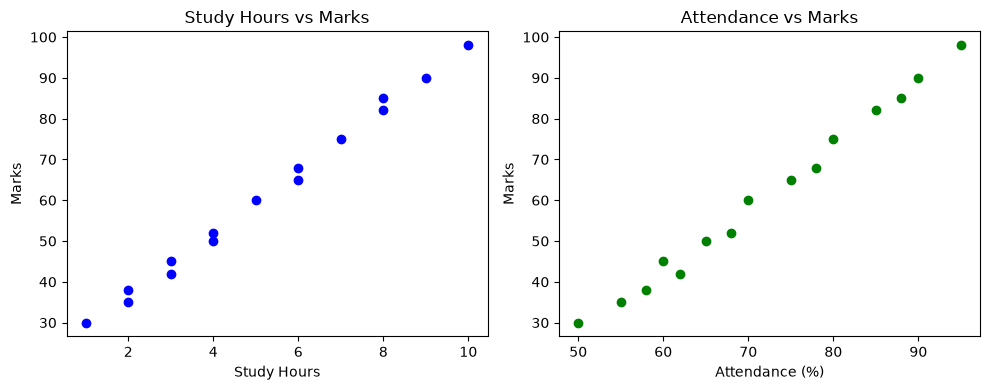

In [7]:
#Create a figure containing two bar plots comparing Units Sold and Revenue by product. Identify the highest and lowest products for each metric, calculate each product's percentage contribution to total revenue, and explain why the product with the highest unit sales may not generate the highest revenue.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Create the dataset
df = pd.DataFrame({
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 2, 4, 6, 8, 3],
    "Attendance": [50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 58, 68, 78, 88, 62],
    "Marks": [30, 35, 45, 50, 60, 65, 75, 82, 90, 98, 38, 52, 68, 85, 42]
})

# Step 2: Calculate Pearson correlation
r1 = np.corrcoef(df["Study_Hours"], df["Marks"])[0, 1]
r2 = np.corrcoef(df["Attendance"], df["Marks"])[0, 1]

print("Study Hours vs Marks:", round(r1, 4))
print("Attendance vs Marks:", round(r2, 4))

# Step 3: Create scatter plots
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(df["Study_Hours"], df["Marks"], color="blue")
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Study Hours vs Marks")

plt.subplot(1, 2, 2)
plt.scatter(df["Attendance"], df["Marks"], color="green")
plt.xlabel("Attendance (%)")
plt.ylabel("Marks")
plt.title("Attendance vs Marks")

plt.tight_layout()
plt.show()


Updated Study Hours vs Marks: 0.7012
Updated Attendance vs Marks: 0.9964


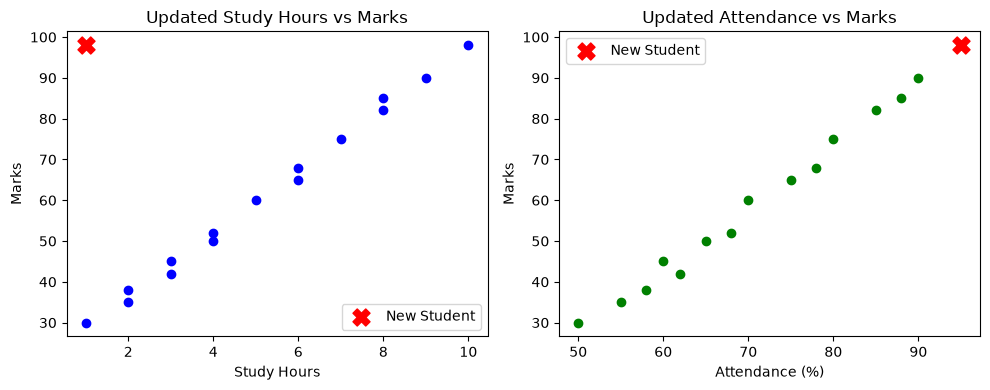

In [8]:
#Add a hypothetical student with 1 study hour, 95% attendance, and 98 marks. Recalculate both correlations and visualize the updated data. Explain how this observation affects the correlation coefficients and why a single unusual observation can influence statistical conclusions.


# Step 1: Add a new student
new_student = pd.DataFrame({
    "Study_Hours": [1],
    "Attendance": [95],
    "Marks": [98]
})

df_new = pd.concat([df, new_student], ignore_index=True)

# Step 2: Recalculate correlations
r1_new = np.corrcoef(
    df_new["Study_Hours"], df_new["Marks"]
)[0, 1]

r2_new = np.corrcoef(
    df_new["Attendance"], df_new["Marks"]
)[0, 1]

print("Updated Study Hours vs Marks:", round(r1_new, 4))
print("Updated Attendance vs Marks:", round(r2_new, 4))

# Step 3: Visualize updated data
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(df_new["Study_Hours"], df_new["Marks"],
            color="blue")
plt.scatter(1, 98, color="red", marker="X",
            s=150, label="New Student")
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Updated Study Hours vs Marks")
plt.legend()

plt.subplot(1, 2, 2)
plt.scatter(df_new["Attendance"], df_new["Marks"],
            color="green")
plt.scatter(95, 98, color="red", marker="X",
            s=150, label="New Student")
plt.xlabel("Attendance (%)")
plt.ylabel("Marks")
plt.title("Updated Attendance vs Marks")
plt.legend()

plt.tight_layout()
plt.show()


      Product  Units_Sold  Revenue
0      Laptop          45  2250000
1      Mobile         120  1800000
2      Tablet          60   600000
3  Headphones          90   270000
4     Monitor          35   525000
5    Keyboard         100   200000


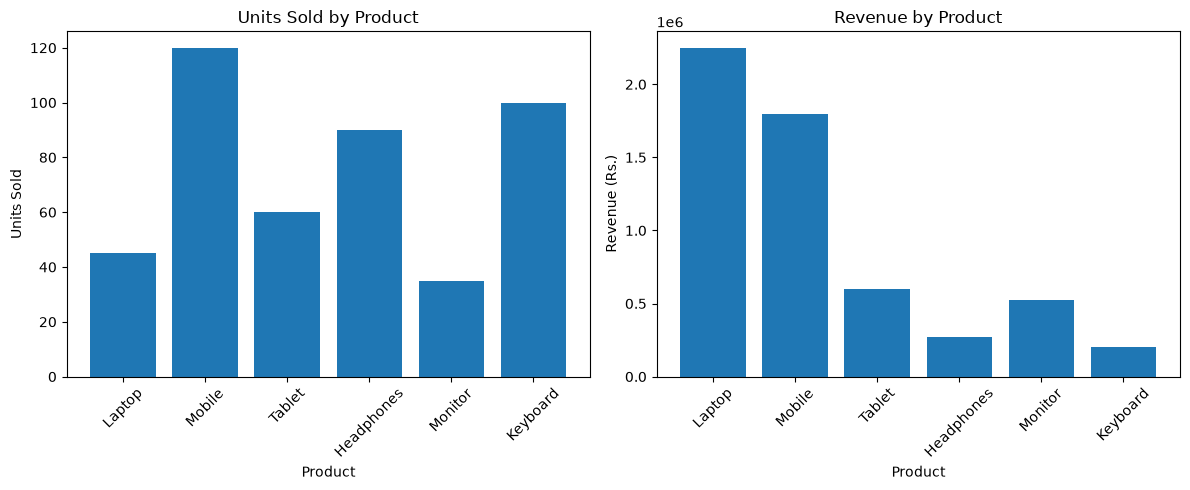

In [10]:
#Create a figure containing two bar plots comparing Units Sold and Revenue by product. Identify the highest and lowest products for each metric, calculate each product's percentage contribution to total revenue, and explain why the product with the highest unit sales may not generate the highest revenue.


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Product": ["Laptop", "Mobile", "Tablet",
                "Headphones", "Monitor", "Keyboard"],
    "Units_Sold": [45, 120, 60, 90, 35, 100],
    "Revenue": [2250000, 1800000, 600000,
                270000, 525000, 200000]
})

print(df)


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.bar(df["Product"], df["Units_Sold"])
plt.title("Units Sold by Product")
plt.xlabel("Product")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
plt.bar(df["Product"], df["Revenue"])
plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue (Rs.)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()



In [11]:
print("Highest Units Sold:",
      df.loc[df["Units_Sold"].idxmax(), "Product"])

print("Lowest Units Sold:",
      df.loc[df["Units_Sold"].idxmin(), "Product"])

print("Highest Revenue:",
      df.loc[df["Revenue"].idxmax(), "Product"])

print("Lowest Revenue:",
      df.loc[df["Revenue"].idxmin(), "Product"])

Highest Units Sold: Mobile
Lowest Units Sold: Monitor
Highest Revenue: Laptop
Lowest Revenue: Keyboard


In [ ]:

#Calculate revenue per unit for every product and create a bar plot ranking products by this metric. Use Python to identify products with high unit sales but comparatively low revenue per unit, and recommend how the store should interpret these three metrics together.

df["Revenue_Per_Unit"] = df["Revenue"] / df["Units_Sold"]

ranked_df = df.sort_values(
    by="Revenue_Per_Unit", ascending=False
)



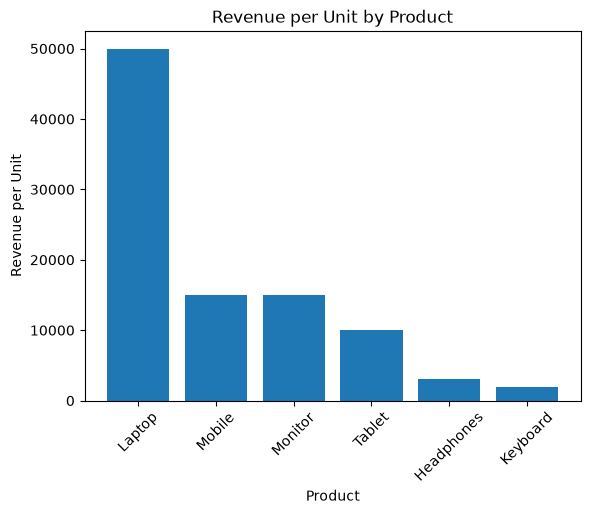

In [15]:

plt.bar(ranked_df["Product"],
        ranked_df["Revenue_Per_Unit"])

plt.xlabel("Product")
plt.ylabel("Revenue per Unit")
plt.title("Revenue per Unit by Product")
plt.xticks(rotation=45)
plt.show()


avg_units = df["Units_Sold"].mean()
avg_revenue_unit = df["Revenue_Per_Unit"].mean()

result = df[
    (df["Units_Sold"] > avg_units) &
    (df["Revenue_Per_Unit"] < avg_revenue_unit)
]

Total Bill vs Tip: 0.6757
Party Size vs Tip: 0.4893


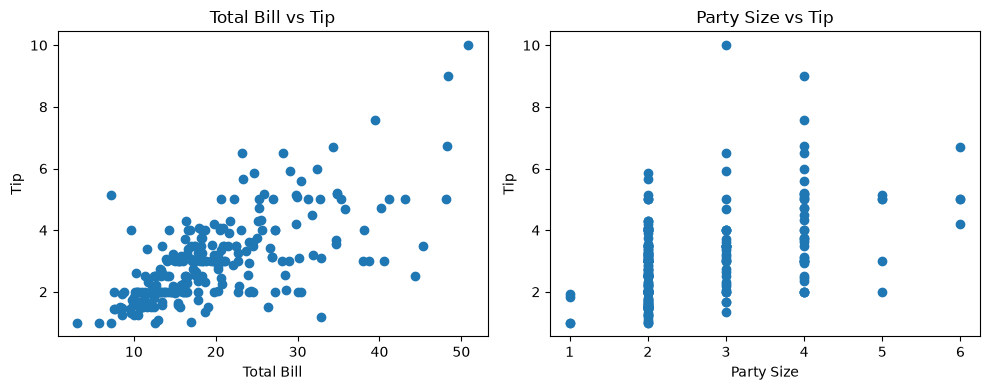

In [4]:
#Create scatter plots for total_bill vs tip and size vs tip. Calculate the Pearson correlation coefficients for both relationships. Identify which pair has the stronger linear association and explain how the scatter plots support or challenge the numerical results.


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the built-in tips dataset
df = sns.load_dataset("tips")

# Calculate Pearson correlations
r1 = df["total_bill"].corr(df["tip"])
r2 = df["size"].corr(df["tip"])

print("Total Bill vs Tip:", round(r1, 4))
print("Party Size vs Tip:", round(r2, 4))

# Create two scatter plots
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(df["total_bill"], df["tip"])
plt.xlabel("Total Bill")
plt.ylabel("Tip")
plt.title("Total Bill vs Tip")

plt.subplot(1, 2, 2)
plt.scatter(df["size"], df["tip"])
plt.xlabel("Party Size")
plt.ylabel("Tip")
plt.title("Party Size vs Tip")

plt.tight_layout()
plt.show()


size
1    1.44
2    2.58
3    3.39
4    4.14
5    4.03
6    5.22
Name: tip, dtype: float64


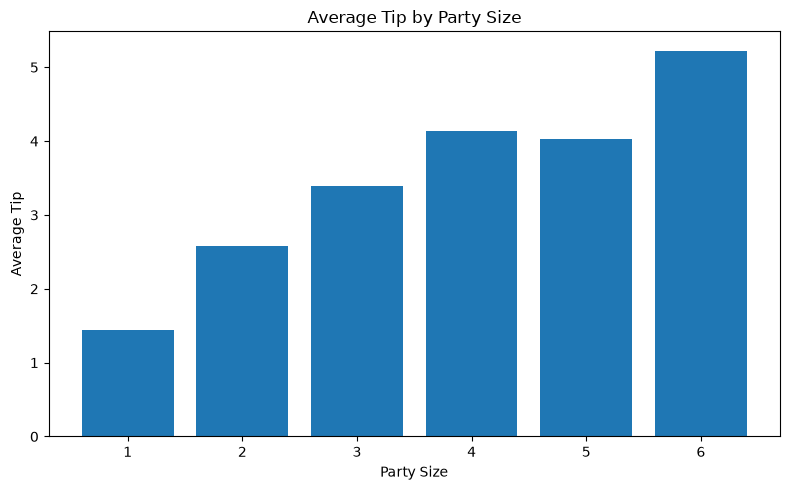

In [5]:
#Group the dataset by party size and calculate the average tip for each group. Create a bar plot of the average tip by party size, then compare the pattern in the grouped bar plot with the correlation between size and tip. Explain why grouped averages and individual-level correlation can tell different stories.

# Group data by party size and calculate average tip
avg_tip = df.groupby("size")["tip"].mean()

print(avg_tip.round(2))


plt.figure(figsize=(8, 5))

plt.bar(avg_tip.index, avg_tip.values)

plt.xlabel("Party Size")
plt.ylabel("Average Tip")
plt.title("Average Tip by Party Size")

plt.tight_layout()
plt.show()


In [14]:

#Create scatter plots for Advertising Cost vs Sales and Advertising Cost vs Customer Satisfaction. Calculate both Pearson correlation coefficients, classify each relationship as positive, negative, or weak, and justify your classifications using numerical evidence

import pandas as pd
import matplotlib.pyplot as plt

df=pd.DataFrame({"Campaign": ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J"],
    "Advertising_Cost": [10, 15, 20, 25, 30, 35, 40, 45, 50, 55],
    "Sales": [90, 80, 75, 70, 65, 60, 55, 50, 45, 40],
    "Customer_Satisfaction": [60, 75, 55, 85, 65, 70, 50, 80, 60, 75]}
)



Sales correlation: -0.996
Satisfaction correlation: 0.089


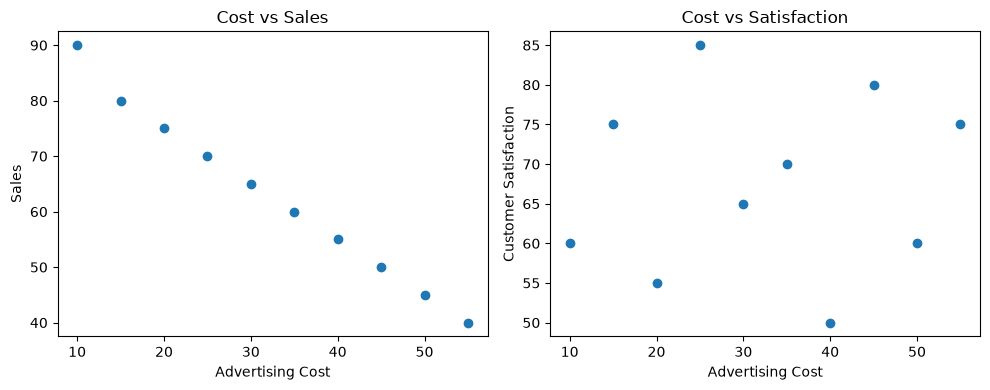

In [13]:

# Calculate Pearson correlation
r1 = df["Advertising_Cost"].corr(df["Sales"])
r2 = df["Advertising_Cost"].corr(df["Customer_Satisfaction"])

print("Sales correlation:", round(r1, 3))
print("Satisfaction correlation:", round(r2, 3))

# Scatter plots
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(df["Advertising_Cost"], df["Sales"])
plt.xlabel("Advertising Cost")
plt.ylabel("Sales")
plt.title("Cost vs Sales")

plt.subplot(1, 2, 2)
plt.scatter(df["Advertising_Cost"], df["Customer_Satisfaction"])
plt.xlabel("Advertising Cost")
plt.ylabel("Customer Satisfaction")
plt.title("Cost vs Satisfaction")

plt.tight_layout()
plt.show()


New correlation: 0.568


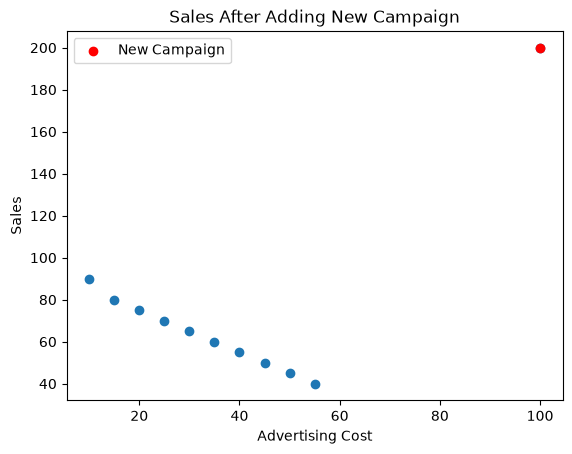

In [11]:
# Add a new campaign with an advertising cost of 100 and sales of 200. Recalculate the correlation between advertising cost and sales, plot the new point, and explain why correlation does not establish causation or guarantee that increased advertising will produce increased sales.


import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Advertising_Cost": [10, 15, 20, 25, 30, 35, 40, 45, 50, 55],
    "Sales": [90, 80, 75, 70, 65, 60, 55, 50, 45, 40],
    "Customer_Satisfaction": [60, 75, 55, 85, 65, 70, 50, 80, 60, 75]
})

# New campaign add
df.loc[len(df)] = [100, 200, 75]

new_corr = df["Advertising_Cost"].corr(df["Sales"])
print("New correlation:", round(new_corr, 3))

plt.scatter(df["Advertising_Cost"], df["Sales"])
plt.scatter([100], [200], color="red", label="New Campaign")
plt.xlabel("Advertising Cost")
plt.ylabel("Sales")
plt.title("Sales After Adding New Campaign")
plt.legend()
plt.show()
